# 04 Corridor B graphs

**Delay-based numbers here are SIMULATED** (medium scenario, `data/processed/sim/medium/`). Timetable-only graphs use only the cleaned timetable. The ground-truth cascade table is **not** read in this notebook (validation only, Phase 5).

Time split (configs/splits.yaml): **train = all of 2024 + Jan-Aug 2025, validation = Sep-Oct 2025, test = Nov-Dec 2025**, strictly by time. Delay attributes below use the **training window** (the 2024 run and the 2025 run of the medium scenario) unless stated.

In [1]:
import os, sys
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
sys.path.insert(0, ".")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx, folium
from branca.colormap import LinearColormap
from src.graph import station_graph as sg, train_graph as tg
from src.graph.timetable import load_timetable, section_passages
from src.graph.snapshot import snapshot

from src import splits
G = Path("data/processed/graph"); SCEN = splits.sources("medium")
TRAIN = splits.window_tag("train"); ALL = splits.window_tag("analysis_all_2025")
nodes = pd.read_parquet(G / "station_nodes.parquet"); edges = pd.read_parquet(G / "station_edges.parquet")
nd = pd.read_parquet(G / f"station_nodes_delay_{TRAIN}.parquet"); ed = pd.read_parquet(G / f"station_edges_delay_{TRAIN}.parquet")
nd_all = pd.read_parquet(G / f"station_nodes_delay_{ALL}.parquet"); ed_all = pd.read_parquet(G / f"station_edges_delay_{ALL}.parquet")
tnodes = pd.read_parquet(G / "train_nodes.parquet"); tedges = pd.read_parquet(G / "train_edges.parquet")
sgraph = sg.load_pickle(G / "station_graph_timetable.pkl")
tt = load_timetable()
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
BLUE, ORANGE = "#1f6f9f", "#d98c1f"
print(f"station graph: {sgraph.number_of_nodes()} nodes, {sgraph.number_of_edges()} directed edges; train graph: {len(tnodes)} trains, {len(tedges)} edges")
print(tedges.type.value_counts().to_dict())

station graph: 108 nodes, 214 directed edges; train graph: 225 trains, 1964 edges
{'section_sharing': 734, 'overtake_section': 587, 'overtake_station': 425, 'rake': 218}


## 1. The corridor on a map (colour: mean arrival delay in the training window (2024 + Jan-Aug 2025), SIMULATED; size: scheduled trains per day)

In [2]:
n = nodes.merge(nd, on="node")
cmap = LinearColormap(["#fee8c8", "#fdbb84", "#e34a33", "#7f0000"], vmin=n.mean_arrival_delay.min(), vmax=n.mean_arrival_delay.max(),
                      caption="Mean arrival delay, training window 2024-01-01 .. 2025-08-31 (minutes) - SIMULATED")
m = folium.Map(location=[n.lat.mean(), n.lon.mean()], zoom_start=6, tiles="OpenStreetMap")
und = edges[edges.direction == 1]
for r in und.itertuples():
    a, b = nodes.loc[r.from_node], nodes.loc[r.to_node]
    folium.PolyLine([(a.lat, a.lon), (b.lat, b.lon)], color="#888888", weight=1 + r.trains_per_day / 25, opacity=0.6).add_to(m)
for r in n.itertuples():
    folium.CircleMarker((r.lat, r.lon), radius=3 + r.trains_per_day / 14, color=cmap(r.mean_arrival_delay), fill=True, fill_opacity=0.85,
                        weight=1, tooltip=f"{r.node_name} ({r.display_name}): {r.trains_per_day} trains/day, {r.halts_per_day} halts/day, "
                        f"mean delay {r.mean_arrival_delay:.1f} min [SIMULATED]").add_to(m)
cmap.add_to(m)
Path("reports/figures").mkdir(parents=True, exist_ok=True)
m.save("reports/figures/corridor_map_SIMULATED.html")
m

## 2. The chain with junctions marked

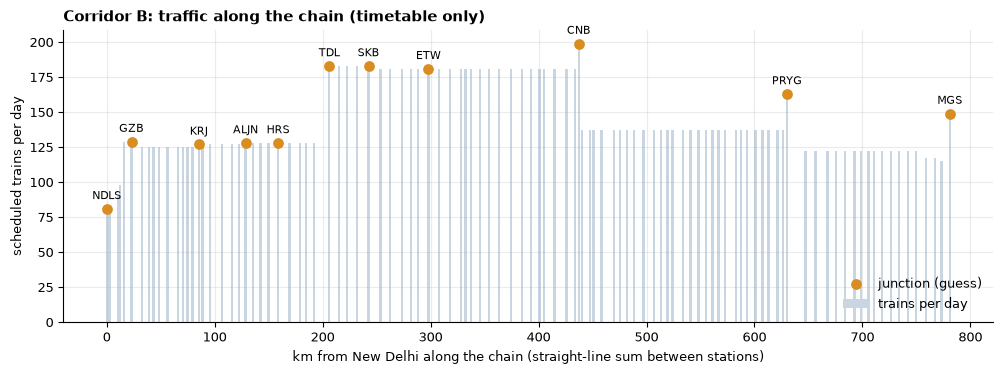

node_name                                                 display_name  trains_per_day  halts_per_day
     NDLS                                                    NEW DELHI              81             81
      GZB                                                    GHAZIABAD             129             46
      KRJ                                                    KHURJA JN             127             24
     ALJN                                                   ALIGARH JN             128             57
      HRS                                                   HATHRAS JN             128             21
      TDL                                                    TUNDLA JN             183             90
      SKB                                                SHIKOHABAD JN             183             42
      ETW                                                       ETAWAH             181             59
      CNB                                               KANPUR CENTRAL            

In [3]:
fig, ax = plt.subplots(figsize=(12, 3.8))
x = nodes.km_from_new_delhi
ax.bar(x, nodes.trains_per_day, width=2.2, color="#c9d6e2", label="trains per day")
j = nodes[nodes.is_junction]
ax.scatter(j.km_from_new_delhi, j.trains_per_day, color=ORANGE, s=45, zorder=3, label="junction (guess)")
for r in j.itertuples():
    ax.annotate(r.node_name, (r.km_from_new_delhi, r.trains_per_day), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set_xlabel("km from New Delhi along the chain (straight-line sum between stations)"); ax.set_ylabel("scheduled trains per day")
ax.legend(frameon=False, loc="lower right"); ax.set_title("Corridor B: traffic along the chain (timetable only)", loc="left", fontweight="bold"); plt.show()
print(nodes[nodes.is_junction][["node_name", "display_name", "trains_per_day", "halts_per_day"]].to_string(index=False))

## 3. Traffic and degree distributions

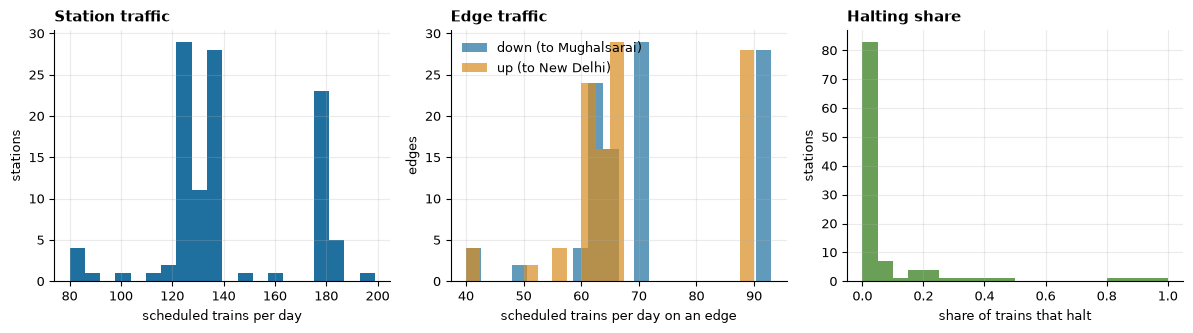

station graph in/out degree values: [1, 2] [1, 2] (a chain: end nodes 1, others 2)


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].hist(nodes.trains_per_day, bins=20, color=BLUE); axes[0].set_xlabel("scheduled trains per day"); axes[0].set_ylabel("stations"); axes[0].set_title("Station traffic", loc="left", fontweight="bold")
for d, c, lab in ((1, BLUE, "down (to Mughalsarai)"), (-1, ORANGE, "up (to New Delhi)")):
    axes[1].hist(edges[edges.direction == d].trains_per_day, bins=20, alpha=0.7, color=c, label=lab)
axes[1].set_xlabel("scheduled trains per day on an edge"); axes[1].set_ylabel("edges"); axes[1].legend(frameon=False); axes[1].set_title("Edge traffic", loc="left", fontweight="bold")
axes[2].hist(nodes.halts_per_day / nodes.trains_per_day.clip(lower=1), bins=20, color="#6a9f58"); axes[2].set_xlabel("share of trains that halt"); axes[2].set_ylabel("stations")
axes[2].set_title("Halting share", loc="left", fontweight="bold"); plt.tight_layout(); plt.show()
deg_in = dict(sgraph.in_degree()); deg_out = dict(sgraph.out_degree())
print("station graph in/out degree values:", sorted(set(deg_in.values())), sorted(set(deg_out.values())), "(a chain: end nodes 1, others 2)")

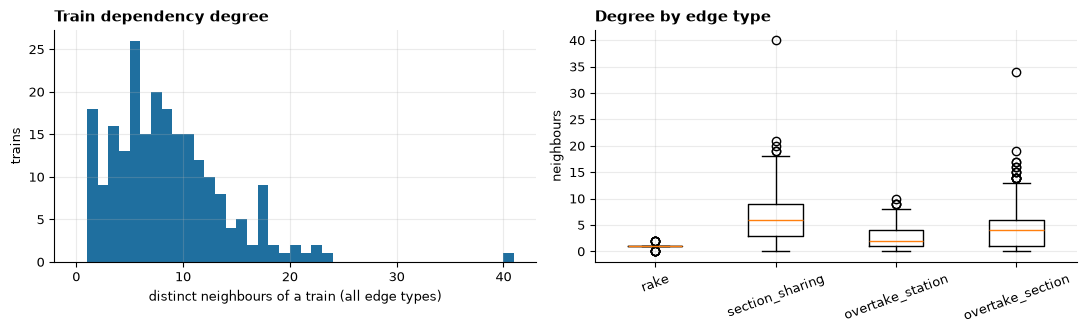

                  mean  50%   max
overtake_section   4.8  4.0  34.0
overtake_station   2.7  2.0  10.0
rake               1.0  1.0   2.0
section_sharing    6.5  6.0  40.0
all                8.1  7.0  40.0

most connected trains:
       overtake_section  overtake_station  rake  section_sharing  all                                              name          type
13040                34                 6     0               40   40                                    Janata Express  Mail/Express
22409                13                10     1               19   23       Sasaram-Anand ViharT Delhi GariRath Express     Superfast
19570                13                 9     1               17   22                      Varanasi Okha Weekly Express  Mail/Express
12329                16                 7     1               21   22                        West Bengal Sampark Kranti     Superfast
12379                19                 8     1               20   21              Sealdah - Amritsar 

In [5]:
deg = tg.degree_summary(tedges, tnodes)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(deg["all"], bins=range(0, deg["all"].max() + 2), color=BLUE); axes[0].set_xlabel("distinct neighbours of a train (all edge types)"); axes[0].set_ylabel("trains")
axes[0].set_title("Train dependency degree", loc="left", fontweight="bold")
types = ["rake", "section_sharing", "overtake_station", "overtake_section"]
axes[1].boxplot([deg[t] for t in types], tick_labels=types); axes[1].set_ylabel("neighbours"); axes[1].tick_params(axis="x", rotation=20)
axes[1].set_title("Degree by edge type", loc="left", fontweight="bold"); plt.tight_layout(); plt.show()
print(deg.describe().round(1).T[["mean", "50%", "max"]])
top = deg.sort_values("all", ascending=False).head(8).join(tnodes.set_index("train")[["name", "type"]])
print("\nmost connected trains:"); print(top.to_string())
print("\nedges by type: count, mean scheduled gap (min)"); print(tedges.groupby("type").agg(edges=("count", "size"), total_count=("count", "sum"), mean_gap=("mean_gap_min", "mean")).round(2))

## 4. Scheduled trains per hour for three sections (both directions)

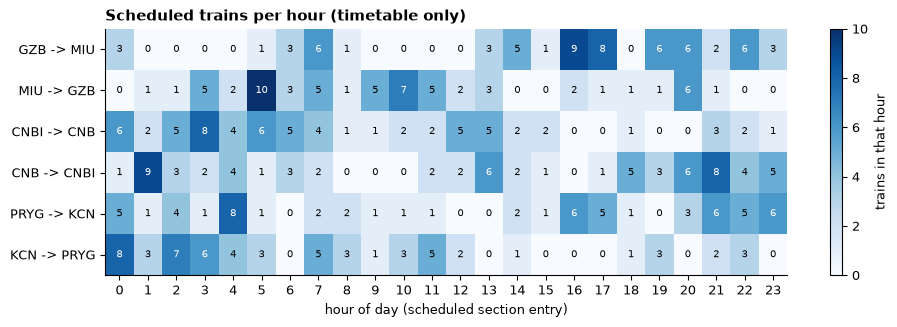

In [6]:
names = nodes.set_index("node_name").node
want = [("GZB", "MIU"), ("CNBI", "CNB"), ("PRYG", "KCN")]
rows, labels = [], []
for a, b in want:
    for lo_, hi_ in ((a, b), (b, a)):
        e_ = edges[(edges.from_node == names[lo_]) & (edges.to_node == names[hi_])]
        if len(e_):
            rows.append(e_[[f"trains_hour_{h:02d}" for h in range(24)]].iloc[0].to_numpy()); labels.append(f"{lo_} -> {hi_}")
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(np.array(rows), aspect="auto", cmap="Blues")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels); ax.set_xticks(range(24)); ax.set_xlabel("hour of day (scheduled section entry)")
for i in range(len(rows)):
    for h in range(24):
        ax.text(h, i, int(rows[i][h]), ha="center", va="center", fontsize=7, color="white" if rows[i][h] > np.max(rows) / 2 else "black")
ax.grid(False); plt.colorbar(im, label="trains in that hour"); ax.set_title("Scheduled trains per hour (timetable only)", loc="left", fontweight="bold"); plt.show()

## 5. Query check: neighbours of Kanpur and trains per edge

In [7]:
cnb = int(names["CNB"])
q = pd.DataFrame([{"direction": "to " + sgraph.nodes[v]["node_name"], "edge": f"CNB -> {sgraph.nodes[v]['node_name']}", "trains_per_day": d["trains_per_day"],
                   "mean_sched_run_min": round(d["mean_sched_run_min"], 2), "share_fast": round(d["share_fast"], 2)} for _, v, d in sgraph.out_edges(cnb, data=True)] +
                 [{"direction": "from " + sgraph.nodes[u]["node_name"], "edge": f"{sgraph.nodes[u]['node_name']} -> CNB", "trains_per_day": d["trains_per_day"],
                   "mean_sched_run_min": round(d["mean_sched_run_min"], 2), "share_fast": round(d["share_fast"], 2)} for u, _, d in sgraph.in_edges(cnb, data=True)])
print("Kanpur Central:", sgraph.nodes[cnb]["trains_per_day"], "trains/day,", sgraph.nodes[cnb]["halts_per_day"], "halts/day")
print(q.to_string(index=False))

Kanpur Central: 199 trains/day, 187 halts/day
direction        edge  trains_per_day  mean_sched_run_min  share_fast
  to CNBI CNB -> CNBI              70                2.57        0.76
   to GOY  CNB -> GOY              89                3.20        0.69
 from GOY  GOY -> CNB              92                3.66        0.67
from CNBI CNBI -> CNB              67                3.32        0.78


## 6. Training-window vs full-2025 delay attributes (SIMULATED)

The two versions are computed by the same date-range functions; only the training-window version may be used to fit or choose anything. The full-year version is for analysis.

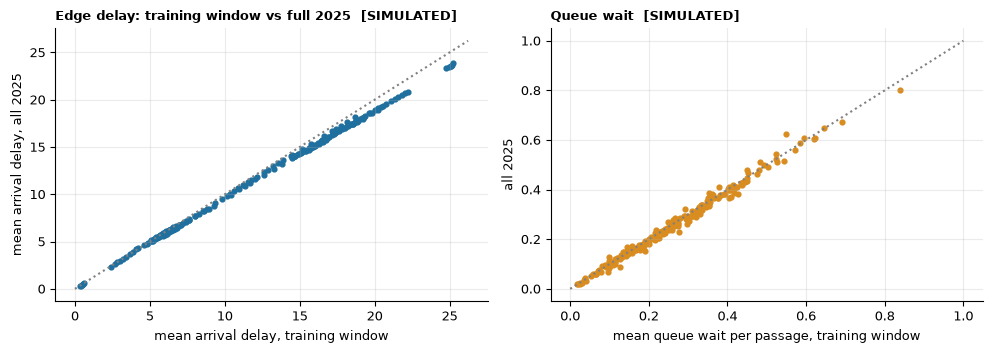

passages per edge, training window vs full 2025: 9132639 5474480 | correlation of mean delay: 1.0
edges: mean delay added across a section (min): train -0.009 range -0.18 to 0.75


In [8]:
a = ed.set_index(["from_node", "to_node"]); b = ed_all.set_index(["from_node", "to_node"])
j = a[["mean_arrival_delay", "mean_delay_added", "mean_queue_wait_per_passage", "n_passages"]].join(b[["mean_arrival_delay", "mean_delay_added", "mean_queue_wait_per_passage", "n_passages"]], lsuffix="_train", rsuffix="_all")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(j.mean_arrival_delay_train, j.mean_arrival_delay_all, s=12, color=BLUE); lim = [0, j[["mean_arrival_delay_train", "mean_arrival_delay_all"]].max().max() + 1]
axes[0].plot(lim, lim, color="grey", ls=":"); axes[0].set_xlabel("mean arrival delay, training window"); axes[0].set_ylabel("mean arrival delay, all 2025"); axes[0].set_title("Edge delay: training window vs full 2025  [SIMULATED]", loc="left", fontweight="bold", fontsize=9)
axes[1].scatter(j.mean_queue_wait_per_passage_train, j.mean_queue_wait_per_passage_all, s=12, color=ORANGE); axes[1].plot([0, 1], [0, 1], color="grey", ls=":")
axes[1].set_xlabel("mean queue wait per passage, training window"); axes[1].set_ylabel("all 2025"); axes[1].set_title("Queue wait  [SIMULATED]", loc="left", fontweight="bold", fontsize=9)
plt.tight_layout(); plt.show()
print("passages per edge, training window vs full 2025:", int(j.n_passages_train.sum()), int(j.n_passages_all.sum()), "| correlation of mean delay:", round(j.mean_arrival_delay_train.corr(j.mean_arrival_delay_all), 3))
print("edges: mean delay added across a section (min): train", round(ed.mean_delay_added.mean(), 3), "range", round(ed.mean_delay_added.min(), 2), "to", round(ed.mean_delay_added.max(), 2))

## 7. Snapshot lookup (SIMULATED delays): who is at or approaching each station

Shown for the first fog day of January at 18:00 (SIMULATED weather). This only demonstrates the lookup; no features are built.

In [9]:
wx = pd.read_parquet(Path(SCEN[-1].dir) / "weather.parquet")
fog_day = str(wx[(wx.state == "fog") & (pd.to_datetime(wx.date).dt.month == 1)].date.min().date())
print("snapshot date:", fog_day, "18:00")
s = snapshot(SCEN, fog_day, 18, tt)
print(len(s), "train-node rows;", s.state.value_counts().to_dict(), "| trains in corridor:", s.train.nunique())
by = s.groupby(["node_name", "state"]).agg(trains=("train", "nunique"), mean_delay=("current_delay_min", "mean")).round(1).unstack(fill_value=0)
print(by.sort_values(("trains", "in_section"), ascending=False).head(8))
print("\nlate trains right now (delay >= 30 min):")
print(s[s.current_delay_min >= 30].sort_values("current_delay_min", ascending=False).head(6)[["node_name", "train", "type", "state", "current_delay_min"]].to_string(index=False))

snapshot date: 2025-01-03 18:00


74 train-node rows; {'in_section': 63, 'at_station': 11} | trains in corridor: 74
              trains            mean_delay           
state     at_station in_section at_station in_section
node_name                                            
JJK                0          3        0.0       20.3
KNS                0          3        0.0       17.4
SNS                0          3        0.0       23.4
SB                 0          3        0.0        4.0
HRS                0          3        0.0        8.5
EKL                0          3        0.0       26.6
ARW                0          2        0.0       10.6
DKDE               2          2        5.3        4.7

late trains right now (delay >= 30 min):
node_name train         type      state  current_delay_min
      KGA 12488    Superfast at_station         143.399796
     PRYG 18102 Mail/Express at_station         140.413788
      MNJ 12820    Superfast in_section         108.833672
     SYWN 12826    Superfast in_section       

## Notes

* `station_graph_timetable.pkl` and `train_graph_timetable.pkl` contain no delays. Delay versions are in `station_graph_delays_SIMULATED_*.pkl`.
* The ground-truth cascade tables sit in the scenario folder and are deliberately not used anywhere in this notebook.